# Image Classification with a Fully Connected Network

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/03-10-ANN-Image-Classification.ipynb)

So far the inputs of our networks were numbers or one-hot encoded words. In this chapter the input is an **image**. We use the simplest possible approach: flatten the pixel grid into one long row vector and feed it to the networks from the previous chapters ([logistic regression with a hidden layer](03-06-ANN-Logistic-Regression.ipynb) and [regression](03-05-ANN-Multiple-Regression.ipynb)). We use the notation of those chapters: observations are the rows of the data matrix $X$ ($n \times p$), $W_h$ is the hidden-layer weight matrix ($p \times k$), $W_o$ the output-layer weights, $Z = \varphi(X W_h + b_h)$ the hidden activations.

We work with the UTKFace data [@ZHANG2017AgeProgressionRegression] and solve two tasks with the same architecture:

- **classification**: is the person on the photo male or female (binary cross-entropy, as in the logistic regression chapter);
- **regression**: how old is the person (squared error, as in the regression chapters).

The main goal is not accuracy but to **look inside the network**: because every hidden neuron has one weight per pixel, its weights can be displayed as an image.

## Images as Data

A grayscale image is a grid of $h \times w$ pixel intensities. Flattening writes the rows of the grid one after another, so a $32 \times 32$ image becomes a vector with $p = 1024$ entries:

$$
\underbrace{\begin{pmatrix} x_{11} & x_{12} & \cdots & x_{1w} \\ \vdots & & & \vdots \\ x_{h1} & x_{h2} & \cdots & x_{hw} \end{pmatrix}}_{h \times w \text{ image}} \;\longrightarrow\; \underbrace{\begin{pmatrix} x_{11} & \cdots & x_{1w} & x_{21} & \cdots & x_{hw} \end{pmatrix}}_{1 \times p \text{ row of } X}, \qquad p = h \cdot w
$$

The network treats the 1024 pixels as 1024 unrelated predictors: it does not know which pixels are neighbours. All spatial structure has to be learned from the data (the order of the columns could be shuffled and the result would be the same, as long as the shuffle is the same for all images). This is the main limitation that convolutional networks remove.

## The Data

UTKFace contains about 23,700 photographs of faces that are already **aligned and cropped** (the face is centred and has similar size on all images). The age and the gender (0 = male, 1 = female) are encoded in the file names `age_gender_race_date.jpg`. The data is available for non-commercial research purposes only.

We convert the images to $32 \times 32$ grayscale, keep people up to 80 years (older ages are rare) and split the data into training (70%), validation (15%) and test (15%) sets. The pixels are standardized with the **training** mean and standard deviation of each pixel.

In [1]:
import io
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split

DATA_DIR = Path("data")
ARCHIVE = DATA_DIR / "UTKFace.tar.gz"
CACHE = DATA_DIR / "utkface_32.npz"
ARCHIVE_URL = "https://huggingface.co/datasets/py97/UTKFace-Cropped/resolve/main/UTKFace.tar.gz"
IMAGE_SIZE = 32

In [2]:
def build_cache():
    # Read the faces straight from the archive, convert to grayscale and shrink
    DATA_DIR.mkdir(exist_ok=True)
    if not ARCHIVE.exists():
        urllib.request.urlretrieve(ARCHIVE_URL, ARCHIVE)

    images, ages, genders = [], [], []
    with tarfile.open(ARCHIVE) as tar:
        for member in tar:
            if not (member.isfile() and member.name.endswith(".jpg")):
                continue
            fields = member.name.split("/")[-1].split("_")
            try:
                age, gender = int(fields[0]), int(fields[1])
            except ValueError:
                continue
            if gender not in (0, 1):
                continue
            image = Image.open(io.BytesIO(tar.extractfile(member).read()))
            image = image.convert("L").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
            images.append(np.asarray(image, dtype=np.uint8))
            ages.append(age)
            genders.append(gender)
    np.savez_compressed(CACHE, images=np.stack(images), age=ages, gender=genders)

if not CACHE.exists():
    build_cache()

data = np.load(CACHE)
keep = data["age"] <= 80
images = data["images"][keep]          # (n, 32, 32), uint8
age = data["age"][keep].astype(np.float32)
female = data["gender"][keep].astype(np.float32)

print("images:", images.shape, " share of women:", female.mean().round(3))

images: (23168, 32, 32)  share of women: 0.473


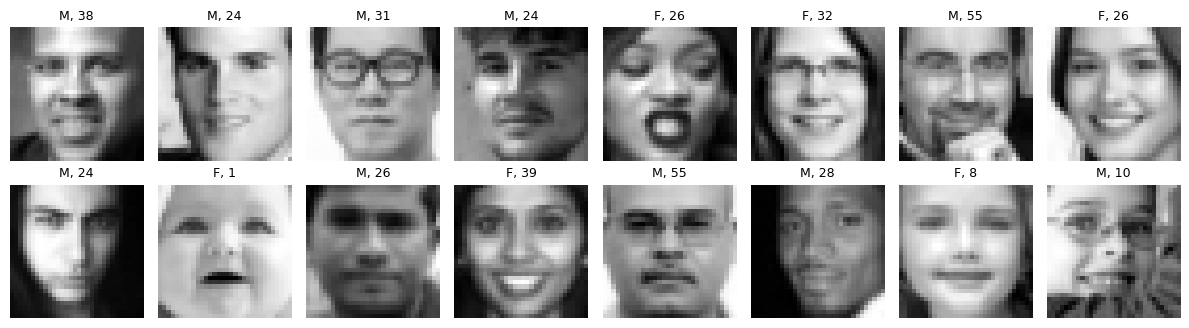

In [3]:
# no-ex-class
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.ravel(), rng.choice(len(age), 16, replace=False)):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"{'F' if female[i] else 'M'}, {int(age[i])}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

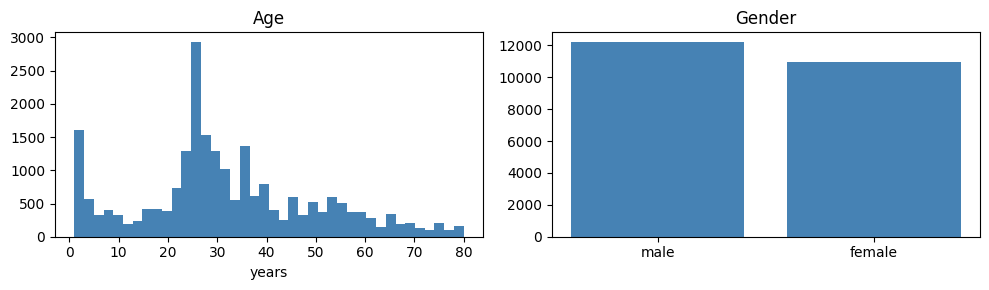

In [4]:
# no-ex-class
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(age, bins=40, color="steelblue")
axes[0].set(title="Age", xlabel="years")
axes[1].bar(["male", "female"], [(female == 0).sum(), (female == 1).sum()], color="steelblue")
axes[1].set(title="Gender")
plt.tight_layout()
plt.show()

In [5]:
# Flatten, split (stratified by gender) and standardize with training statistics
X_raw = images.reshape(len(images), -1).astype(np.float32) / 255

idx_train, idx_rest = train_test_split(np.arange(len(age)), test_size=0.3, random_state=0, stratify=female)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, random_state=0, stratify=female[idx_rest])

pixel_mean = X_raw[idx_train].mean(axis=0)
pixel_std = X_raw[idx_train].std(axis=0) + 1e-6

def standardize(X):
    return (X - pixel_mean) / pixel_std

X_all = torch.tensor(standardize(X_raw))
y_female = torch.tensor(female)
y_age = torch.tensor(age)

print("train / val / test:", len(idx_train), len(idx_val), len(idx_test))

train / val / test: 16217 3475 3476


## Gender Classification

### Baselines

A model is only useful if it beats simple alternatives. We use two baselines:

1. predicting the **majority class** in the training data;
2. **logistic regression** on the pixels, i.e. a network without a hidden layer: $\hat{y} = \sigma(x w + b)$.

Logistic regression has one weight per pixel, so its weights form a single "template" image. This will be useful for the weight analysis below.

### The network

The network has one hidden layer with $k = 64$ ReLU neurons and one output neuron. With $p = 1024$ pixels it has $1024 \cdot 64 + 64 + 64 + 1 = 65{,}729$ parameters, about four times more than the 16,217 training images, so overfitting is a real risk. We therefore

- use the Adam optimizer with mini-batches of 128 images,
- add a small L2 penalty (`weight_decay`), and
- keep the weights of the epoch with the lowest **validation** loss (early stopping). The test set is used only once, at the end.

:::{.ex-class}
$$
\hat{y}_i = \sigma\left( \varphi(x_i W_h + b_h) W_o + b_o \right), \qquad
L = -\frac{1}{n}\sum_{i=1}^n \left[ y_i \log \hat{y}_i + (1 - y_i)\log (1-\hat{y}_i) \right]
$$
:::

where $y_i = 1$ for women. In PyTorch `BCEWithLogitsLoss` applies the sigmoid inside the loss, so the model returns the logit.

In [6]:
def fit(model, loss_fn, target, n_epochs=60, learning_rate=1e-3, weight_decay=0.0, batch_size=128, seed=0):
    # Mini-batch Adam; returns the model with the best validation loss and the learning curves
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    X_train, y_train = X_all[idx_train], target[idx_train]
    X_val, y_val = X_all[idx_val], target[idx_val]

    history = {"train": [], "val": []}
    best_loss, best_state = float("inf"), None
    for epoch in range(n_epochs):
        model.train()
        order = torch.randperm(len(idx_train))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss_fn(model(X_train[batch]).squeeze(1), y_train[batch]).backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            history["train"].append(loss_fn(model(X_train).squeeze(1), y_train).item())
            history["val"].append(loss_fn(model(X_val).squeeze(1), y_val).item())
        if history["val"][-1] < best_loss:
            best_loss = history["val"][-1]
            best_state = {name: value.clone() for name, value in model.state_dict().items()}
            history["best_epoch"] = epoch

    model.load_state_dict(best_state)
    return model, history

def predict(model, rows):
    model.eval()
    with torch.no_grad():
        return model(X_all[rows]).squeeze(1)

In [7]:
bce = nn.BCEWithLogitsLoss()
N_HIDDEN = 64

majority_accuracy = max(female[idx_test].mean(), 1 - female[idx_test].mean())

torch.manual_seed(0)
logreg = nn.Linear(X_all.shape[1], 1)
logreg, hist_logreg = fit(logreg, bce, y_female)

torch.manual_seed(0)
gender_net = nn.Sequential(nn.Linear(X_all.shape[1], N_HIDDEN), nn.ReLU(), nn.Linear(N_HIDDEN, 1))
initial_hidden_weights = gender_net[0].weight.detach().clone()   # keep for the weight analysis
gender_net, hist_gender = fit(gender_net, bce, y_female, weight_decay=1e-3)

def accuracy(model, rows):
    return ((predict(model, rows) > 0).float() == y_female[rows]).float().mean().item()

print(f"Majority class : {majority_accuracy:.3f}")
print(f"Logistic regr. : {accuracy(logreg, idx_test):.3f}")
print(f"ANN (k={N_HIDDEN})    : {accuracy(gender_net, idx_test):.3f}   (test accuracy)")

Majority class : 0.527
Logistic regr. : 0.853
ANN (k=64)    : 0.871   (test accuracy)


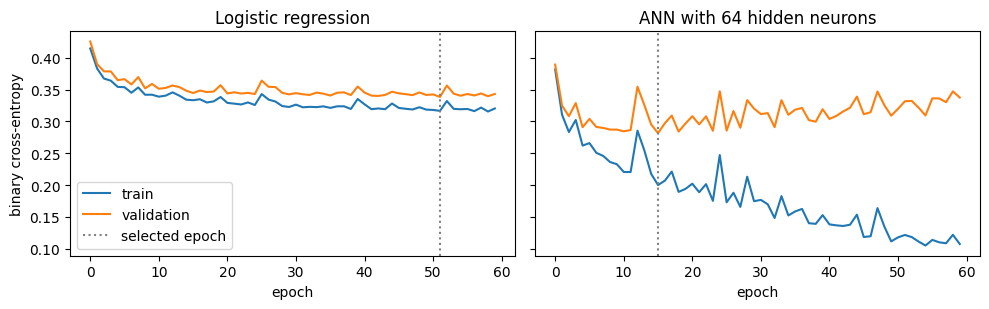

In [8]:
# no-ex-class
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, history, title in zip(axes, [hist_logreg, hist_gender], ["Logistic regression", "ANN with 64 hidden neurons"]):
    ax.plot(history["train"], label="train")
    ax.plot(history["val"], label="validation")
    ax.axvline(history["best_epoch"], color="gray", linestyle=":", label="selected epoch")
    ax.set(title=title, xlabel="epoch")
axes[0].set_ylabel("binary cross-entropy")
axes[0].legend()
plt.tight_layout()
plt.show()

The hidden layer improves on logistic regression by about two percentage points (85% to 87%). Both models are clearly better than the majority class. Let us see where the ANN makes mistakes.

rows: truth (M, F), columns: prediction (M, F)
[[1603  229]
 [ 219 1425]]


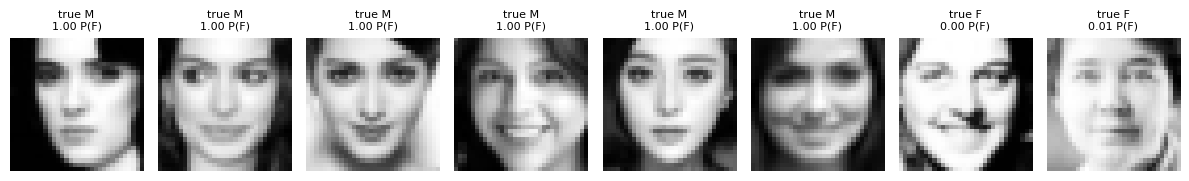

In [9]:
logits_test = predict(gender_net, idx_test)
pred_test = (logits_test > 0).float()
truth_test = y_female[idx_test]

confusion = np.array([[((truth_test == t) & (pred_test == p)).sum().item() for p in (0, 1)] for t in (0, 1)])
print("rows: truth (M, F), columns: prediction (M, F)")
print(confusion)

wrong = torch.where(pred_test != truth_test)[0]
# the most confident mistakes
worst = wrong[torch.argsort(-logits_test[wrong].abs())][:8]
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, j in zip(axes, worst):
    i = idx_test[j.item()]
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"true {'F' if female[i] else 'M'}\n{torch.sigmoid(logits_test[j]).item():.2f} P(F)", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Age Regression

For age we keep the architecture and change only the output and the loss: the output neuron is linear (no sigmoid) and the loss is the mean squared error, exactly as in the [multiple regression chapter](03-05-ANN-Multiple-Regression.ipynb). The baseline predicts the training mean age for everybody. We report the mean absolute error (MAE) in years because it is easier to interpret than the MSE.

MAE of predicting the mean age: 14.4 years
MAE of the ANN                : 8.8 years


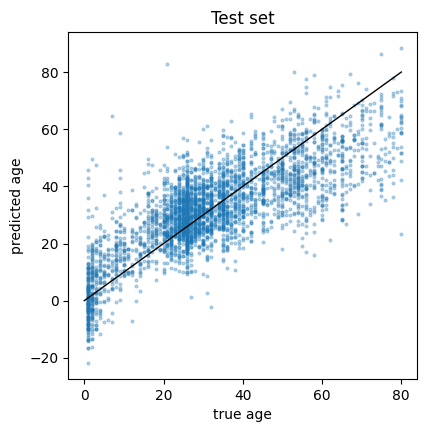

In [10]:
mse = nn.MSELoss()

torch.manual_seed(0)
age_net = nn.Sequential(nn.Linear(X_all.shape[1], N_HIDDEN), nn.ReLU(), nn.Linear(N_HIDDEN, 1))
age_net, hist_age = fit(age_net, mse, y_age, weight_decay=1e-3)

age_pred = predict(age_net, idx_test)
mae_net = (age_pred - y_age[idx_test]).abs().mean().item()
mae_mean = (y_age[idx_test] - y_age[idx_train].mean()).abs().mean().item()
print(f"MAE of predicting the mean age: {mae_mean:.1f} years")
print(f"MAE of the ANN                : {mae_net:.1f} years")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y_age[idx_test], age_pred, s=4, alpha=0.3)
ax.plot([0, 80], [0, 80], color="black", linewidth=1)
ax.set(xlabel="true age", ylabel="predicted age", title="Test set")
plt.show()

The network is much better than the constant prediction, but the typical error is still about 8-9 years. The scatter plot shows the typical regression-to-the-mean pattern: the network overestimates the age of the youngest and underestimates the age of the oldest people, because extreme ages are rare and a wrong guess towards the middle is cheaper in terms of squared error.

## Analysis of the Learned Weights

Each hidden neuron $m$ computes $z_m = \varphi\left(\sum_{j=1}^{p} x_j w_{h,jm} + b_{h,m}\right)$. The $m$-th column of $W_h$ has one weight per pixel, so we can reshape it to $32 \times 32$ and display it as an image. Because the inputs are standardized, the neuron is strongly activated by images that look like its weight image: it is a **template matcher**. Positive weights (red) mark pixels where a brighter-than-average value increases the activation, negative weights (blue) mark pixels where a darker-than-average value does.

Note that PyTorch stores the weights of `nn.Linear` as an (out, in) matrix, i.e. $W_h^\top$. Row $m$ of `weight` is the weight image of neuron $m$.

### Weights Before and After Training

Initial weights (random noise), first 8 neurons


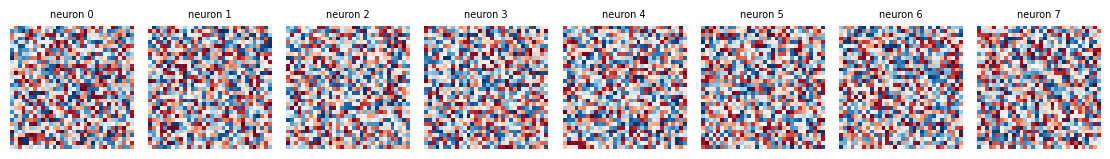

Trained weights, first 8 neurons


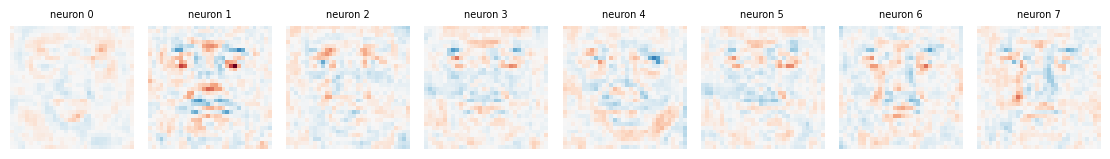

In [11]:
# no-ex-class
def show_filters(weights, titles, n_cols=8, size=1.4):
    # weights: (m, 1024) tensor, shown as images with a colour scale centred at 0
    n_rows = int(np.ceil(len(weights) / n_cols))
    limit = weights.abs().max().item()
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * size, n_rows * size * 1.15))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, w, title in zip(np.ravel(axes), weights, titles):
        ax.imshow(w.reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set_title(title, fontsize=7)
    plt.tight_layout()
    plt.show()

trained_hidden_weights = gender_net[0].weight.detach()
output_weights = gender_net[2].weight.detach().squeeze(0)      # one weight per hidden neuron

print("Initial weights (random noise), first 8 neurons")
show_filters(initial_hidden_weights[:8], [f"neuron {m}" for m in range(8)])
print("Trained weights, first 8 neurons")
show_filters(trained_hidden_weights[:8], [f"neuron {m}" for m in range(8)])

In [12]:
# no-ex-class
def neighbour_correlation(weights):
    # correlation between the weights of horizontally neighbouring pixels (averaged over neurons)
    grid = weights.reshape(-1, IMAGE_SIZE, IMAGE_SIZE)
    left, right = grid[:, :, :-1].reshape(-1), grid[:, :, 1:].reshape(-1)
    return torch.corrcoef(torch.stack([left, right]))[0, 1].item()

print(f"neighbouring-pixel weight correlation, initial: {neighbour_correlation(initial_hidden_weights):.2f}")
print(f"neighbouring-pixel weight correlation, trained: {neighbour_correlation(trained_hidden_weights):.2f}")
print(f"mean |weight|, initial: {initial_hidden_weights.abs().mean():.4f}   trained: {trained_hidden_weights.abs().mean():.4f}")

neighbouring-pixel weight correlation, initial: -0.01
neighbouring-pixel weight correlation, trained: 0.68
mean |weight|, initial: 0.0156   trained: 0.0229


The initial weights are noise: neighbouring pixels have unrelated weights. Training has produced weight images with spatial structure (neighbouring pixels get similar weights) even though the network was never told which pixels are neighbours. It has discovered the structure from the data alone, because neighbouring pixels are strongly correlated in face images. The weights have also grown (mean absolute weight from 0.016 to 0.023), but only moderately, which is expected with early stopping and weight decay. The weight images of the most influential neurons (next figure) are concentrated on the eyes, eyebrows and mouth: the network has found that these regions carry the most information about gender in aligned faces, while the background and the forehead get weights close to zero.

### The Most Influential Neurons

A hidden neuron contributes $z_m w_{o,m}$ to the logit. A neuron with a large positive output weight $w_{o,m}$ pushes the prediction towards "female" when it is active, a neuron with a negative output weight towards "male". We display the neurons with the largest $|w_{o,m}|$.

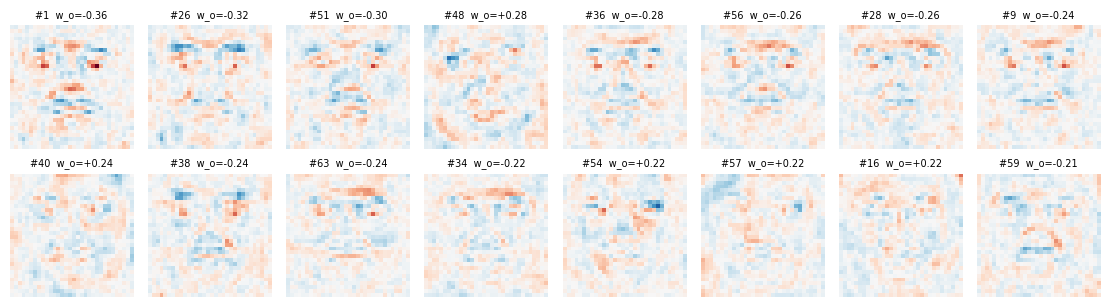

In [13]:
# no-ex-class
top = torch.argsort(-output_weights.abs())[:16]
show_filters(trained_hidden_weights[top], [f"#{m.item()}  w_o={output_weights[m]:+.2f}" for m in top], n_cols=8)

To see what a neuron responds to, we look at the test images with the highest activation. We also compare the average contribution $z_m w_{o,m}$ of the neuron for men and women.

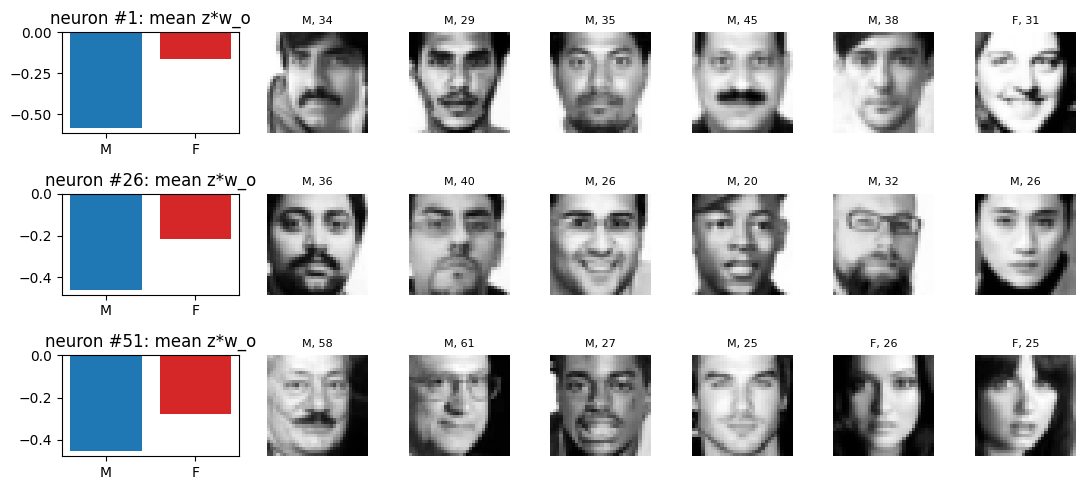

In [14]:
# no-ex-class
with torch.no_grad():
    Z_test = torch.relu(X_all[idx_test] @ trained_hidden_weights.T + gender_net[0].bias)

contribution = Z_test * output_weights                      # (n_test, k): z_m * w_o,m
is_female = y_female[idx_test] == 1

fig, axes = plt.subplots(3, 7, figsize=(11, 5), gridspec_kw={"width_ratios": [1.4, 1, 1, 1, 1, 1, 1]})
for row, m in enumerate(top[:3].tolist()):
    best = torch.argsort(-Z_test[:, m])[:6]
    axes[row, 0].bar(["M", "F"], [contribution[~is_female, m].mean().item(), contribution[is_female, m].mean().item()],
                     color=["tab:blue", "tab:red"])
    axes[row, 0].set(title=f"neuron #{m}: mean z*w_o")
    for ax, j in zip(axes[row, 1:], best):
        i = idx_test[j.item()]
        ax.imshow(images[i], cmap="gray")
        ax.set_title(f"{'F' if female[i] else 'M'}, {int(age[i])}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

### Comparison with Simple Summaries of the Data

Is the network learning something that we could have found without it? We compare three images that all describe "what separates women from men" in this data set:

1. the logistic regression weights;
2. the difference between the mean standardized female and male face;
3. the *linearized* template of the ANN: $\sum_m w_{o,m} W_{h,\cdot m}$. This is what the network would use if all ReLUs were active; it is not exact, but it summarizes the 64 weight images in one.

correlations between the three images:
[[1.   0.17 0.9 ]
 [0.17 1.   0.22]
 [0.9  0.22 1.  ]]


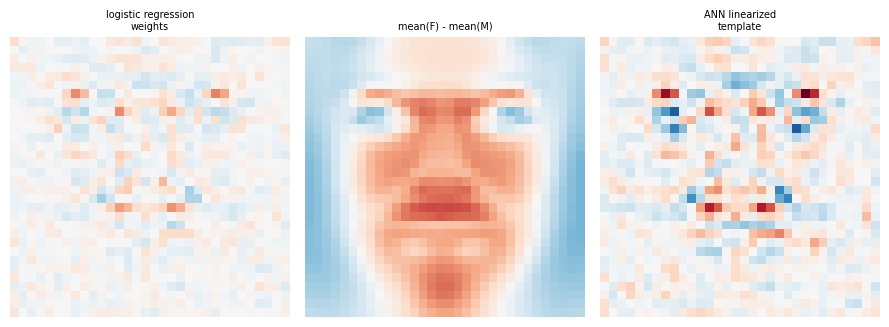

In [15]:
# no-ex-class
logreg_template = logreg.weight.detach().squeeze(0)
mean_difference = X_all[idx_train][y_female[idx_train] == 1].mean(0) - X_all[idx_train][y_female[idx_train] == 0].mean(0)
ann_template = output_weights @ trained_hidden_weights          # (1024,)

templates = torch.stack([logreg_template, mean_difference, ann_template])
print("correlations between the three images:")
print(torch.corrcoef(templates).numpy().round(2))

show_filters(templates, ["logistic regression\nweights", "mean(F) - mean(M)", "ANN linearized\ntemplate"], n_cols=3, size=3)

The logistic regression weights and the ANN template are strongly correlated (about 0.9), so the hidden layer refines the same eye and mouth pattern. Both are almost unrelated to the mean difference (correlation about 0.2), which looks completely different: it is a smooth image with large areas (the lower face and the cheeks are lighter for women, the sides of the head are darker because of the hair). The mean difference is a *description* of the data: it contains every pixel that differs between the groups, including many that are redundant given other pixels. The weights are *predictive*: a pixel with a large weight is useful **after** accounting for all other pixels, and with 1024 strongly correlated predictors the weight of one pixel depends on which other pixels are used. We should therefore be careful when interpreting individual weights as "the important pixels".

### How Many Different Templates Does the Network Use?

If the 64 weight images were independent, the matrix $W_h$ would have 64 equally important directions. We check this with the singular value decomposition (see the [SVD chapter](02-04-SVD.ipynb)) of the trained and the initial weight matrices.

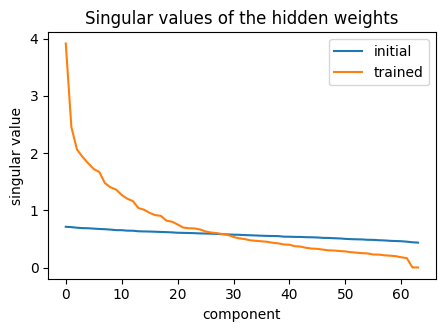

share of the squared weights explained by the first 5 / 10 components: 0.52 / 0.71  (initial: 0.22 for 10)


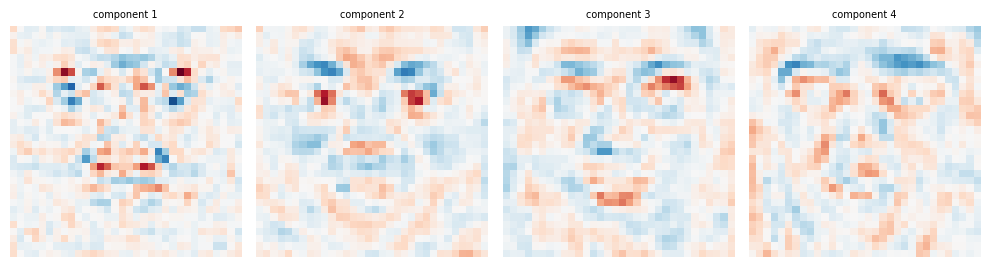

In [16]:
# no-ex-class
singular_trained = torch.linalg.svdvals(trained_hidden_weights)
singular_initial = torch.linalg.svdvals(initial_hidden_weights)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(singular_initial, label="initial")
ax.plot(singular_trained, label="trained")
ax.set(xlabel="component", ylabel="singular value", title="Singular values of the hidden weights")
ax.legend()
plt.show()

share = (singular_trained ** 2).cumsum(0) / (singular_trained ** 2).sum()
print("share of the squared weights explained by the first 5 / 10 components:",
      f"{share[4]:.2f} / {share[9]:.2f}  (initial: {((singular_initial ** 2).cumsum(0) / (singular_initial ** 2).sum())[9]:.2f} for 10)")

_, _, Vt = torch.linalg.svd(trained_hidden_weights, full_matrices=False)
show_filters(Vt[:4], [f"component {c + 1}" for c in range(4)], n_cols=4, size=2.5)

The random initial matrix has a flat spectrum, while the trained matrix is dominated by a few components: many hidden neurons have learned (variations of) the same few templates. The leading components all concentrate on the eyes, eyebrows and mouth, which is the same region that the most influential neurons use.

### The Same Analysis for Age

The age network has the same architecture but a different task. Its most influential neurons (largest $|w_{o,m}|$) are shown below. The sign of $w_{o,m}$ tells whether an active neuron increases (+) or decreases (-) the predicted age. The correlation between the linearized age and gender templates (printed below the figure) is close to zero: the two networks use different pixel patterns, even though they were trained on the same images with the same architecture.

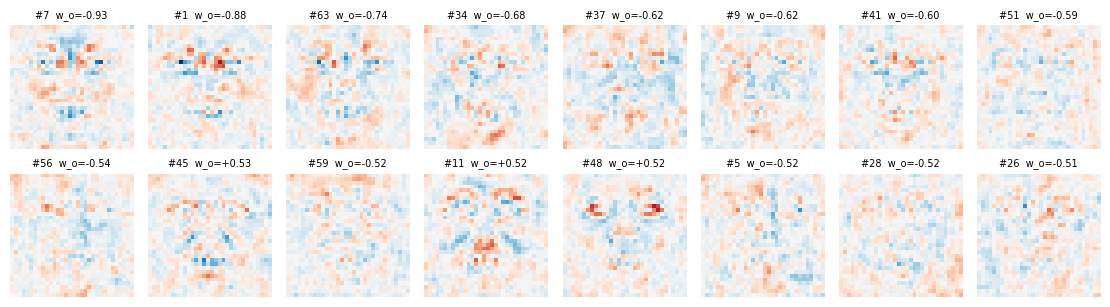

correlation between the linearized age template and the gender template: -0.01


In [17]:
# no-ex-class
age_hidden_weights = age_net[0].weight.detach()
age_output_weights = age_net[2].weight.detach().squeeze(0)
top_age = torch.argsort(-age_output_weights.abs())[:16]
show_filters(age_hidden_weights[top_age], [f"#{m.item()}  w_o={age_output_weights[m]:+.2f}" for m in top_age], n_cols=8)

age_template = age_output_weights @ age_hidden_weights
print("correlation between the linearized age template and the gender template:",
      round(torch.corrcoef(torch.stack([age_template, ann_template]))[0, 1].item(), 2))

### The Weights are Tied to Pixel Positions

Each weight belongs to one fixed pixel position. If the same face is shifted by a few pixels, the template no longer lines up with the face, although a human would not notice any difference. We shift all test images horizontally by $s$ pixels (wrapping around the border) and measure the accuracy of the gender network, which was trained only on centred faces.

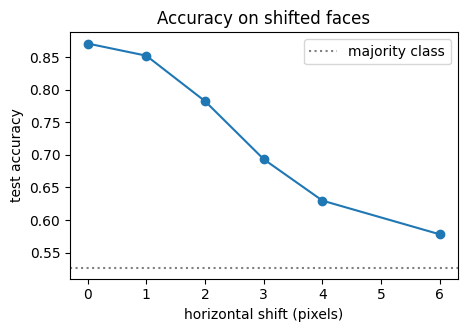

In [18]:
# no-ex-class
shifts = [0, 1, 2, 3, 4, 6]
shifted_accuracy = []
for shift in shifts:
    shifted = np.roll(images[idx_test], shift, axis=2).reshape(len(idx_test), -1).astype(np.float32) / 255
    with torch.no_grad():
        logits = gender_net(torch.tensor(standardize(shifted))).squeeze(1)
    shifted_accuracy.append(((logits > 0).float() == y_female[idx_test]).float().mean().item())

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(shifts, shifted_accuracy, marker="o")
ax.axhline(majority_accuracy, color="gray", linestyle=":", label="majority class")
ax.set(xlabel="horizontal shift (pixels)", ylabel="test accuracy", title="Accuracy on shifted faces")
ax.legend()
plt.show()

The accuracy drops quickly with the shift: from 87% for centred faces to about 78% after two pixels (a shift of only 6% of the image width) and to 58%, close to the majority class, after six pixels. A fully connected network would need training images at all positions to become robust, and it would have to learn the same eye detector separately for each position. A **convolutional** layer solves both problems by using the same small weight image at every position of the picture.

## Summary

- Flattening turns an image into a row of $X$; the networks of the previous chapters can be used unchanged (sigmoid + cross-entropy for gender, linear output + squared error for age).
- With early stopping and weight decay the hidden layer gives a modest gain over logistic regression for gender and a large gain over the constant prediction for age.
- Every hidden neuron's weights are an image. Trained weights show spatial structure that is absent at initialization and are dominated by a few shared templates.
- Weight images are useful for intuition, but individual weights are not reliable measures of pixel importance because pixels are strongly correlated.
- Weights are tied to positions, so the network is not robust to shifts. This motivates convolutional networks.

## Exercises

1. Change the number of hidden neurons (4, 16, 256) and compare validation loss, test accuracy and the weight images. How few neurons are enough?
2. Remove the weight decay. How do the learning curves and the weight images change?
3. Repeat the analysis with $48 \times 48$ images (change `IMAGE_SIZE` and delete the cached file).
4. Treat age as a classification problem with the classes 0-18, 19-40, 41-60, 61+ (softmax output, see the [multi-class chapter](03-07-ANN-Multiclass-Classification.ipynb)). Which classes are confused with each other?
5. Train the gender network on photos of people under 30 only and test it on people over 50. What happens?